# Лабораторный практикум по курсу «Синтез Речи», Университет ИТМО, 2026
**Лабораторная работа №4.** Акустическая модель

**Цель работы:** Обучение акустической модели FastSpeech2 на подготовленных в работах №1-3 данных и оценка того, что получилось.
**Выполнила** Иванова Мария Кирилловна  
**Группа** М4121  
**Преподаватели** Рыбин Сергей Витальевич, Чирковский Артем

In [16]:
import os
import re
import librosa
import numpy as np
import pandas as pd
import soundfile as sf
import librosa.display
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

## 1. Экспериментальная постановка

В работе обучены и сравнены две акустические модели **FastSpeech2**.

- **G2P:** на вход модели подаются фонемы, предсказанные текстовым процессором G2P.
- **GT:** на вход модели подаются эталонные фонемы из разметки MFA.

Архитектура и гиперпараметры обучения для двух запусков одинаковы. Различие между экспериментами только в источнике фонемной последовательности.

## 2. Конфигурация обучения

| Параметр | Значение | Комментарий |
|---|---|---|
| Архитектура | FastSpeech2 | Базовая конфигурация, без предикторов Pitch и Energy |
| Размер скрытого слоя | `hidden_channels=384` | Стандартный размер для FastSpeech2 в coqui |
| Скорость обучения (LR) | `1e-3` | Среднее значение между `1e-4` (очень долго) и `5e-3` (риск расхождения). Позволяет сойтись за разумное время. |
| Размер батча | `32` | Максимальный размер, поместившийся в память GPU |
| Макс. длина аудио | `220500 сэмплов` | Отсечение слишком длинных фраз |

**Вычислительные ресурсы:** GPU NVIDIA GeForce GTX 1080 Ti с объёмом видеопамяти 11 ГБ (11264 MiB).

### 2.1. Продолжительность обучения

| Модель | Начало | Окончание | Продолжительность | Лучший чекпоинт |
|---|---|---|---|---|
| G2P (`baseline_g2p_v2`) | 26 окт., 15:27 | 29 окт., 19:46 | около 3,5 суток | `best_model_309573.pth` |
| GT (`baseline_gt`) | 29 окт., 21:10 | 2 нояб., 16:36 | около 4 суток | `best_model_418329.pth` |

Обе модели обучались с одинаковыми основными гиперпараметрами. В качестве результата каждого запуска использовался лучший сохранённый чекпоинт.


## 3. Динамика обучения

Для контроля обучения рассмотрены две кривые:
- **общий train loss** - изменение суммарной ошибки модели;
- **duration loss** - ошибка предсказания длительностей, важная для согласования фонемной последовательности с временной структурой речи.

На графиках показано скользящее среднее по 50 точкам, чтобы уменьшить визуальный шум исходных значений.

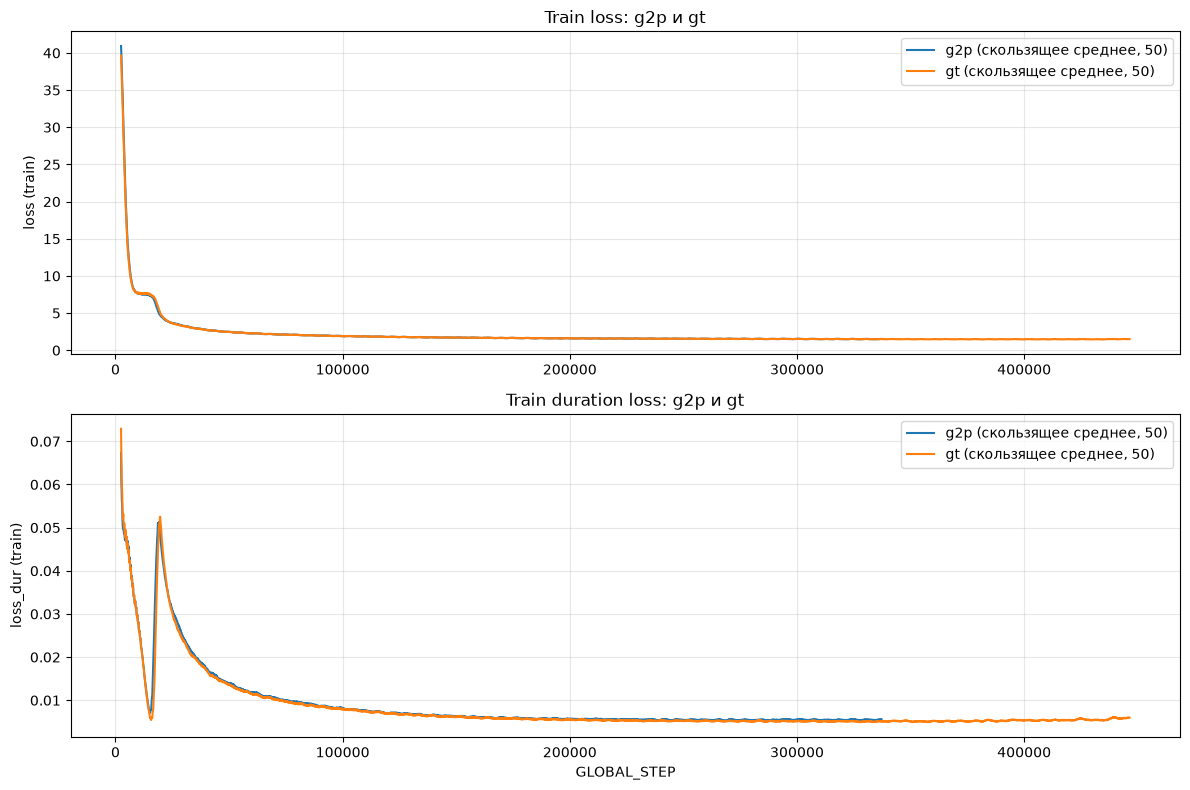

In [2]:
def parse_loss(log_path):
    steps, losses, loss_durs = [], [], []
    cur_step = None
    with open(log_path, encoding="utf-8", errors="ignore") as fh:
        for line in fh:
            m = re.search(r"GLOBAL_STEP:\s*(\d+)", line)
            if m:
                cur_step = int(m.group(1))
                continue
            m = re.search(r"\|\s*>\s*loss:\s*([\d.eE+-]+)", line)
            if m and cur_step is not None:
                losses.append((cur_step, float(m.group(1))))
            m = re.search(r"\|\s*>\s*loss_dur:\s*([\d.eE+-]+)", line)
            if m and cur_step is not None:
                loss_durs.append((cur_step, float(m.group(1))))
    return losses, loss_durs

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
for name, log in [("g2p", "runs_baseline_g2p_v2.log"), ("gt", "runs_baseline_gt.log")]:
    losses, loss_durs = parse_loss(log)
    s, l = zip(*losses);  s, l = list(s), list(l)
    ax1.plot(s, pd.Series(l).rolling(50).mean(), label=f"{name} (скользящее среднее, 50)")

    s, d = zip(*loss_durs); s, d = list(s), list(d)
    ax2.plot(s, pd.Series(d).rolling(50).mean(), label=f"{name} (скользящее среднее, 50)")

ax1.set_ylabel("loss (train)")
ax1.set_title("Train loss: g2p и gt")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.set_xlabel("GLOBAL_STEP"); ax2.set_ylabel("loss_dur (train)")
ax2.set_title("Train duration loss: g2p и gt")
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Комментарий к кривым обучения

При интерпретации графиков важно различать снижение ошибки на обучающей выборке и обобщающую способность модели. По одним только train-кривым нельзя надёжно установить переобучение: для этого необходимо сопоставить их с eval loss на тех же этапах обучения.

В итоговом тексте следует описать наблюдаемую динамику кривых без категоричного вывода о переобучении, если на графике не представлены соответствующие eval-кривые.


## 4. Количественная оценка на отложенной выборке

Для оценки использован набор `data/eval_sentences.csv`, содержащий отложенные предложения. Скрипт `evaluate.py` формирует для каждого предложения три аудиоверсии:

| Вариант | Содержание |
|---|---|
| `natural` | Исходная естественная запись |
| `copysynth` | Исходная mel-спектрограмма, преобразованная обратно в аудио алгоритмом Griffin–Lim |
| `model` | Mel-спектрограмма, предсказанная FastSpeech2 и преобразованная в аудио Griffin–Lim |

`copysynth` служит ориентиром для оценки артефактов самого Griffin–Lim: акустическая модель в этом варианте не участвует.

Используются следующие показатели:
- **MCD (Mel Cepstral Distortion)** - расстояние между мел-кепстральными представлениями эталонной и синтезированной речи.
- **MCD constant** - контрольное значение для постоянной средней mel-спектрограммы.
- **Frame ratio** - отношение числа кадров предсказанной спектрограммы к числу кадров эталонной.
- **Диапазон mel** - минимальные и максимальные значения mel-спектрограммы. Сравнение с эталоном позволяет проверить сопоставимость масштаба.

In [15]:
runs = {
    "G2P": {
        "run_dir": Path("runs/baseline_g2p_v2"),
        "log": Path("evaluate_g2p.log"),
    },
    "GT": {
        "run_dir": Path("runs/baseline_gt"),
        "log": Path("evaluate_gt.log"),
    },
}

EXPECTED = 120
AUDIO_DIRS = ["natural", "copysynth", "model"]

results = {}

for name, paths in runs.items():
    run_dir = paths["run_dir"]
    eval_dir = run_dir / "eval"
    csv_path = eval_dir / "mcd.csv"

    assert csv_path.exists(), f"{name}: не найден {csv_path}"
    assert paths["log"].exists(), f"{name}: не найден лог {paths['log']}"

    df = pd.read_csv(csv_path, sep="|", quoting=3)
    assert len(df) == EXPECTED, (
        f"{name}: в CSV {len(df)} строк вместо {EXPECTED}"
    )

    for folder in AUDIO_DIRS:
        audio_dir = eval_dir / folder
        wav_files = list(audio_dir.glob("*.wav")) if audio_dir.exists() else []
        assert len(wav_files) == EXPECTED, (
            f"{name}/{folder}: {len(wav_files)} WAV вместо {EXPECTED}"
        )

    log_text = paths["log"].read_text(encoding="utf-8")

    natural_match = re.search(
        r"mel range\s+natural:\s*\[\s*([-+\d.]+),\s*([-+\d.]+)\s*\]",
        log_text
    )
    model_match = re.search(
        r"mel range\s+yours\s*:\s*\[\s*([-+\d.]+),\s*([-+\d.]+)\s*\]",
        log_text
    )

    assert natural_match and model_match, (
        f"{name}: не удалось извлечь диапазоны mel из лога"
    )

    natural_range = tuple(map(float, natural_match.groups()))
    model_range = tuple(map(float, model_match.groups()))

    print(f"\n{name}: проверка полноты пройдена")
    print(f"CSV: {len(df)}/{EXPECTED}")
    for folder in AUDIO_DIRS:
        print(f"{folder}: {len(list((eval_dir / folder).glob('*.wav')))}/{EXPECTED}")

    print(f"MCD model    : {df['mcd_model'].mean():.2f} dB "
          f"(median {df['mcd_model'].median():.2f})")
    print(f"MCD constant : {df['mcd_constant'].mean():.2f} dB")
    print(f"Frame ratio  : "
          f"{(df['frames_model'] / df['frames_natural']).mean():.3f}")
    print(f"Natural mel  : {natural_range}")
    print(f"Model mel    : {model_range}")


G2P: проверка полноты пройдена
CSV: 120/120
natural: 120/120
copysynth: 120/120
model: 120/120
MCD model    : 29.20 dB (median 28.56)
MCD constant : 62.50 dB
Frame ratio  : 0.971
Natural mel  : (-11.33, 0.48)
Model mel    : (-11.26, 0.01)

GT: проверка полноты пройдена
CSV: 120/120
natural: 120/120
copysynth: 120/120
model: 120/120
MCD model    : 29.37 dB (median 28.97)
MCD constant : 62.50 dB
Frame ratio  : 0.986
Natural mel  : (-11.33, 0.48)
Model mel    : (-11.18, 0.05)


### 4.1. Интерпретация количественных результатов

Обе модели существенно превосходят вариант с постоянной mel-спектрограммой: MCD составляет 29,20 dB для G2P и 29,37 dB для GT против 62,50 dB у константного baseline.

На выбранном наборе данных и при данной конфигурации заметного преимущества GT-фонем по MCD не наблюдается. MCD у модели, обученной на G2P на 0,17 dB ниже, чем GT. 

Среднее отношение числа кадров близко к единице для обеих моделей (0,971 и 0,986). Диапазоны mel-значений также близки к эталонному.

## 5. Качественная оценка синтеза

### 5.1. Сравнение спектрограмм

Ниже сопоставлены спектрограммы одного и того же предложения `000020`:
- естественная запись;
- копи-синтез исходной mel-спектрограммы через Griffin–Lim;
- синтез модели G2P;
- синтез модели GT.

Сравнение помогает визуально оценить различия между эталонной речью, ограничениями Griffin–Lim и результатами акустических моделей.


/home/ext-ivanova-mk@ad.speechpro.com/ITMO/students-materials/tts_labs_itmo/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


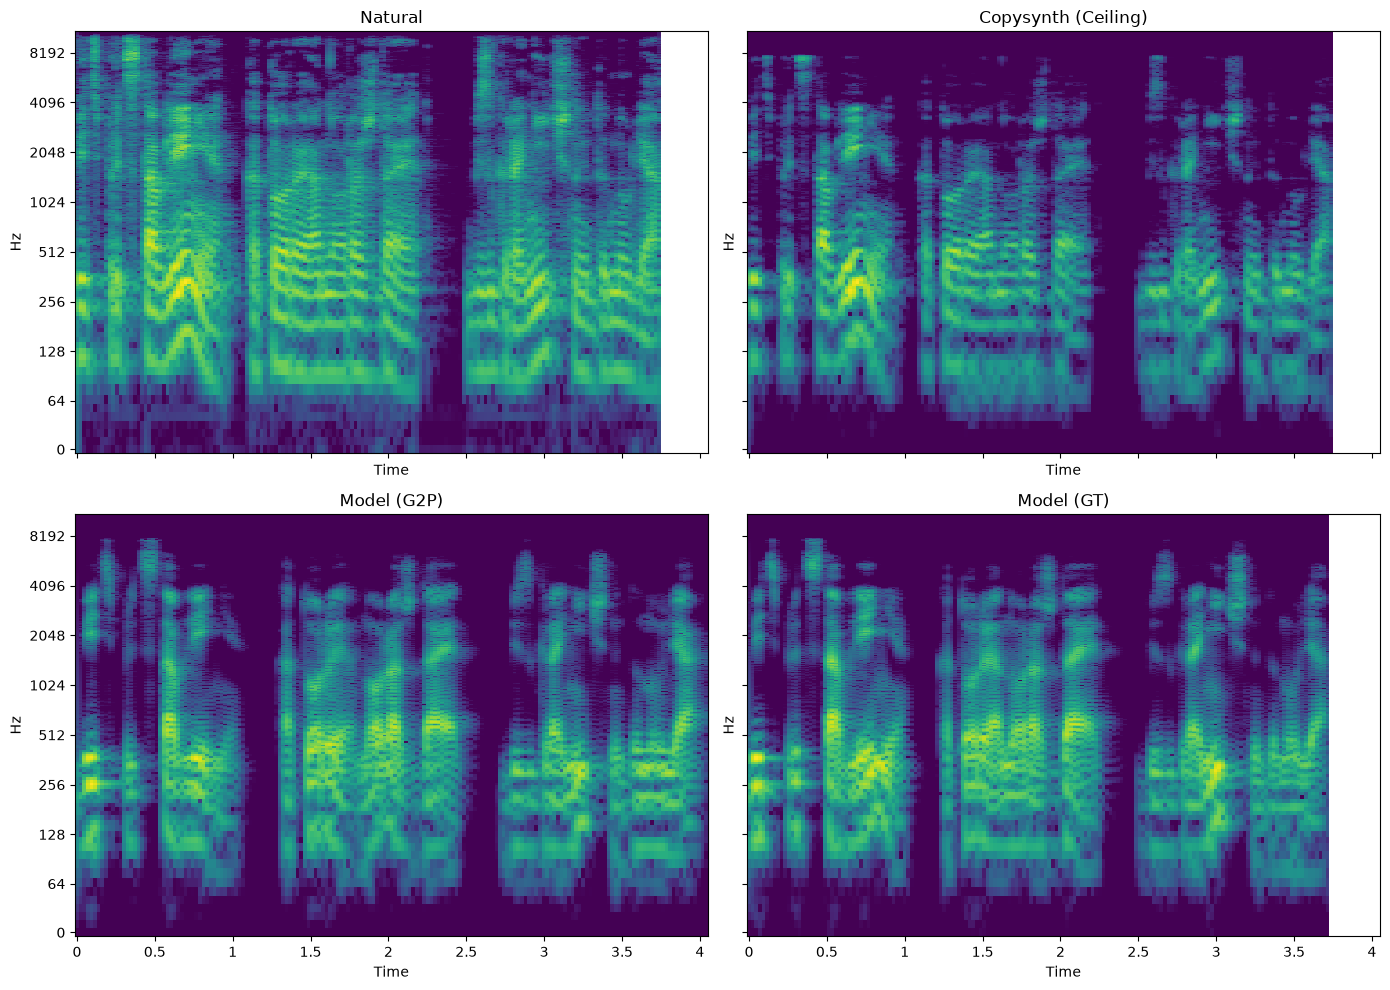

In [ ]:
paths = {
    "Natural": "runs/baseline_g2p_v2/eval/natural/000020_RUSLAN.wav",
    "Copysynth (Ceiling)": "runs/baseline_g2p_v2/eval/copysynth/000020_RUSLAN.wav",
    "Model (G2P)": "runs/baseline_g2p_v2/eval/model/000020_RUSLAN.wav",
    "Model (GT)": "runs/baseline_gt/eval/model/000020_RUSLAN.wav",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (name, path) in zip(axes, paths.items()):
    if not Path(path).exists():
        ax.set_title(f"{name} (файл не найден)")
        continue
        
    y, sr = librosa.load(path, sr=None)
    D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    
    img = librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='log', ax=ax, cmap='viridis')
    ax.set_title(name)

plt.tight_layout()
plt.show()

### 5.2. Слуховая оценка

Для прослушивания выбран пример `000020`. Сопоставляются четыре аудио: естественная запись, копи-синтез, результат модели G2P и результат модели GT.


In [5]:
g2p_wav = Path("runs/baseline_g2p_v2/eval/model/000020_RUSLAN.wav")
gt_wav  = Path("runs/baseline_gt/eval/model/000020_RUSLAN.wav")
natural_wav = Path("runs/baseline_g2p_v2/eval/natural/000020_RUSLAN.wav")
copysynth_wav = Path("runs/baseline_g2p_v2/eval/copysynth/000020_RUSLAN.wav")

for name, path in [("natural", natural_wav),
                   ("copysynth", copysynth_wav),
                   ("g2p", g2p_wav),
                   ("gt", gt_wav)]:
    if path.is_file():
        y, sr = librosa.load(path, sr=None)
        print(f"{name}: {sr} Hz, {len(y)/sr:.2f} с")
        display(Audio(y, rate=sr))
    else:
        print(f"{name}: файл не найден: {path}")

natural: 22050 Hz, 3.75 с


copysynth: 22050 Hz, 3.74 с


g2p: 22050 Hz, 4.04 с


gt: 22050 Hz, 3.72 с


Прослушан пример 000020 в четырёх вариантах:

| Вариант | Что слышно |
|---|---|
| natural | Чистая запись, эталон. |
| copysynth | Звук становится глуше - **Griffin-Lim** неидеально восстанавливает фразу. Разборчивость отличная. |
| g2p (baseline_g2p_v2) | Разборчиво, слышны слова. Голос звучит так как у человека с больным горлом — артефакт Griffin-Lim. |
| gt (baseline_gt) | На слух идентично g2p |

## 6. Итоговые выводы

1. Обучены две базовые акустические модели FastSpeech2, различающиеся источником входных фонем: G2P и GT. Основные гиперпараметры и аудиоконфигурация для моделей были одинаковыми.
2. Обе модели показывают MCD ниже MCD постоянного мела (62,50 dB): 29,20 dB для G2P и 29,37 dB для GT.
3. Среднее отношение числа кадров близко к единице: 0,971 для G2P и 0,986 для GT. Диапазоны mel-значений моделей близки к эталонным.
4. Результаты, полученные при обучении на GT-фонем и G2P, практически идентичны. Разница MCD между моделями мала.
5. Прослушивание примера `000020` показывает, что обе модели формируют разборчивую речь. При этом в синтезе заметны артефакты, связанные в том числе с использованием Griffin–Lim.


## 7. Что осталось неудачным и возможные причины

Несмотря на то что обе модели научились синтезировать разборчивую речь, качество полученного аудио сильно уступает естественной речи. В синтезе заметны артефакты, неестественность тембра и резкость звучания.

Возможные причины: 
- ограничения самого вокодера Griffin–Lim: он восстанавливает фазу спектра приближённо, поэтому итоговое звучание может содержать шум и металлические оттенки даже при достаточно корректной мел-спектрограмме;
- ограниченный объём обучающих данных;
- ошибки предсказания длительностей фонем;
- неидеальная паузация; 
- несовершенство акустической модели.

Основная нерешённая проблема - естественность звучания синтезированной речи. Для её улучшения можно было бы использовать более качественный нейросетевой вокодер, дополнительно исследовать предсказание длительностей и просодических характеристик.